In [0]:
%pip install --upgrade kaggle py7zr

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
import os
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
with open(os.path.expanduser("~/.kaggle/access_token"), "w") as f:
    f.write("")
os.chmod(os.path.expanduser("~/.kaggle/access_token"), 0o600)
print("token written")

token written


In [0]:
import kaggle, os
kaggle.api.authenticate()
kaggle.api.competition_download_files(
    "favorita-grocery-sales-forecasting", path="/tmp/favorita")
print(os.listdir("/tmp/favorita"))

['favorita-grocery-sales-forecasting.zip']


In [0]:
import zipfile, os
with zipfile.ZipFile("/tmp/favorita/favorita-grocery-sales-forecasting.zip") as z:
    z.extractall("/tmp/favorita")
print(os.listdir("/tmp/favorita"))

['oil.csv.7z', 'sample_submission.csv.7z', 'stores.csv.7z', 'holidays_events.csv.7z', 'favorita-grocery-sales-forecasting.zip', 'items.csv.7z', 'train.csv.7z', 'test.csv.7z', 'transactions.csv.7z']


In [0]:
import py7zr, glob, os
for f in glob.glob("/tmp/favorita/*.7z"):
    with py7zr.SevenZipFile(f, mode="r") as z:
        z.extractall(path="/tmp/favorita")
    print("extracted", os.path.basename(f))
print(os.listdir("/tmp/favorita"))

extracted oil.csv.7z
extracted sample_submission.csv.7z
extracted stores.csv.7z
extracted holidays_events.csv.7z
extracted items.csv.7z
extracted train.csv.7z
extracted test.csv.7z
extracted transactions.csv.7z
['oil.csv.7z', 'sample_submission.csv.7z', 'items.csv', 'stores.csv.7z', 'holidays_events.csv', 'train.csv', 'stores.csv', 'holidays_events.csv.7z', 'favorita-grocery-sales-forecasting.zip', 'items.csv.7z', 'train.csv.7z', 'test.csv', 'oil.csv', 'sample_submission.csv', 'test.csv.7z', 'transactions.csv', 'transactions.csv.7z']


In [0]:
spark.sql("CREATE SCHEMA IF NOT EXISTS workspace.foodflow")
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.foodflow.raw")
print("schema + volume ready")

schema + volume ready


In [0]:
import shutil
vol = "/Volumes/workspace/foodflow/raw"
for f in ["stores.csv","items.csv","transactions.csv","oil.csv","holidays_events.csv","train.csv"]:
    shutil.copy(f"/tmp/favorita/{f}", f"{vol}/{f}")
    print("copied", f)

copied stores.csv
copied items.csv
copied transactions.csv
copied oil.csv
copied holidays_events.csv
copied train.csv


In [0]:
def land(csv, table):
    df = (spark.read.option("header",True).option("inferSchema",True)
          .csv(f"/Volumes/workspace/foodflow/raw/{csv}"))
    df.write.format("delta").mode("overwrite").saveAsTable(f"workspace.foodflow.bronze_{table}")
    print(f"bronze_{table}: {df.count():,} rows")
for c,t in [("stores.csv","stores"),("items.csv","items"),
            ("transactions.csv","transactions"),("oil.csv","oil"),
            ("holidays_events.csv","holidays")]:
    land(c,t)

bronze_stores: 54 rows
bronze_items: 4,100 rows
bronze_transactions: 83,488 rows
bronze_oil: 1,218 rows
bronze_holidays: 350 rows


In [0]:
df = (spark.read.option("header",True).option("inferSchema",True)
      .csv("/Volumes/workspace/foodflow/raw/train.csv"))
df.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.bronze_train")
print("bronze_train rows:", df.count())

bronze_train rows: 125497040


In [0]:
display(spark.sql("SELECT * FROM workspace.foodflow.bronze_train LIMIT 10"))

id,date,store_nbr,item_nbr,unit_sales,onpromotion
52693297,2015-07-30,46,418024,8.0,false
52693298,2015-07-30,46,418025,8.0,false
52693299,2015-07-30,46,418026,5.0,false
52693300,2015-07-30,46,418235,7.0,false
52693301,2015-07-30,46,418238,4.0,false
52693302,2015-07-30,46,419729,3.0,false
52693303,2015-07-30,46,420720,7.0,false
52693304,2015-07-30,46,421066,4.0,false
52693305,2015-07-30,46,422452,6.0,false
52693306,2015-07-30,46,426155,8.0,false


In [0]:
display(spark.sql("""
SELECT
  SUM(CASE WHEN unit_sales < 0 THEN 1 ELSE 0 END) AS negative_sales,
  SUM(CASE WHEN unit_sales = 0 THEN 1 ELSE 0 END) AS zero_sales,
  COUNT(*) AS total_rows
FROM workspace.foodflow.bronze_train"""))

negative_sales,zero_sales,total_rows
7795,0,125497040


In [0]:
display(spark.sql("""
SELECT MIN(date) AS min_date, MAX(date) AS max_date,
       COUNT(DISTINCT store_nbr) AS stores,
       COUNT(DISTINCT item_nbr) AS items
FROM workspace.foodflow.bronze_train"""))

min_date,max_date,stores,items
2013-01-01,2017-08-15,54,4036


In [0]:
#Bronze-Phase is done.

In [0]:
#Silver-Phase

In [0]:
from pyspark.sql import functions as F
b = spark.table("workspace.foodflow.bronze_train")
s = (b
    .withColumn("date", F.to_date("date"))
    # onpromotion is null for early dates -> treat as not-on-promo
    .withColumn("onpromotion", F.coalesce(F.col("onpromotion").cast("boolean"), F.lit(False)))
    # negative unit_sales = returns. Flag them, and make a demand column with returns set to 0
    .withColumn("is_return", (F.col("unit_sales") < 0).cast("int"))
    .withColumn("unit_sales_demand", F.when(F.col("unit_sales") < 0, 0.0).otherwise(F.col("unit_sales")))
    .dropDuplicates(["id"]))   # de-dupe on the natural key
s.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.silver_sales")
print("silver_sales rows:", s.count())

silver_sales rows: 125497040


In [0]:
display(spark.sql("""
SELECT
  SUM(CASE WHEN unit_sales_demand < 0 THEN 1 ELSE 0 END) AS neg_in_demand_col,
  SUM(CASE WHEN onpromotion IS NULL THEN 1 ELSE 0 END)   AS null_promo,
  SUM(is_return) AS returns_flagged,
  COUNT(*) AS rows
FROM workspace.foodflow.silver_sales"""))

neg_in_demand_col,null_promo,returns_flagged,rows
0,0,7795,125497040


In [0]:
from pyspark.sql.window import Window
o = spark.table("workspace.foodflow.bronze_oil").withColumn("date", F.to_date("date"))
w_fwd = Window.orderBy("date").rowsBetween(Window.unboundedPreceding, 0)
w_bwd = Window.orderBy("date").rowsBetween(0, Window.unboundedFollowing)
# carry the last known price forward into the gaps (weekends/holidays have no price)
o2 = (o
    .withColumn("oil_price", F.last("dcoilwtico", ignorenulls=True).over(w_fwd))
    # backward-fill any remaining nulls at the start (first row has no prior value)
    .withColumn("oil_price", F.coalesce(F.col("oil_price"), F.first("dcoilwtico", ignorenulls=True).over(w_bwd))))
o2.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.silver_oil")
print("silver_oil rows:", o2.count())

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


silver_oil rows: 1218


In [0]:
display(spark.sql("""
SELECT COUNT(*) AS total,
       COUNT(oil_price) AS filled_prices,
       COUNT(*) - COUNT(oil_price) AS still_missing
FROM workspace.foodflow.silver_oil"""))

total,filled_prices,still_missing
1218,1218,0


In [0]:
display(spark.sql("""
SELECT COUNT(*) AS total,
       COUNT(oil_price) AS filled_prices,
       COUNT(*) - COUNT(oil_price) AS still_missing
FROM workspace.foodflow.silver_oil"""))

total,filled_prices,still_missing
1218,1218,0


In [0]:
h = spark.table("workspace.foodflow.bronze_holidays").withColumn("date", F.to_date("date"))
# A 'transferred' holiday was NOT actually celebrated that day; the real day is a 'Transfer'.
h2 = h.withColumn("is_effective_holiday",
        (((F.col("type").isin("Holiday","Additional","Bridge")) & (F.col("transferred")==False))
         | (F.col("type")=="Transfer")).cast("int"))
h2.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.silver_holidays")
display(spark.sql("SELECT type, transferred, COUNT(*) FROM workspace.foodflow.silver_holidays GROUP BY type, transferred ORDER BY type"))

type,transferred,COUNT(*)
Additional,false,51
Bridge,false,5
Event,false,56
Holiday,true,12
Holiday,false,209
Transfer,false,12
Work Day,false,5


In [0]:
(spark.table("workspace.foodflow.bronze_stores")
   .write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.silver_stores"))
(spark.table("workspace.foodflow.bronze_items")
   .write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.silver_items"))
print("silver_stores + silver_items written")

silver_stores + silver_items written


In [0]:
display(spark.sql("""
SELECT
  (SELECT COUNT(*) FROM workspace.foodflow.bronze_train)              AS bronze_rows,
  (SELECT COUNT(*) FROM workspace.foodflow.silver_sales)             AS silver_rows,
  (SELECT ROUND(SUM(unit_sales),0) FROM workspace.foodflow.bronze_train)  AS bronze_total_sales,
  (SELECT ROUND(SUM(unit_sales),0) FROM workspace.foodflow.silver_sales)  AS silver_total_sales
"""))

bronze_rows,silver_rows,bronze_total_sales,silver_total_sales
125497040,125497040,1.073610269E9,1.073610269E9


In [0]:
display(spark.sql("""
SELECT
  (SELECT COUNT(*) FROM workspace.foodflow.silver_sales s
     LEFT JOIN workspace.foodflow.silver_stores st ON s.store_nbr=st.store_nbr
     WHERE st.store_nbr IS NULL) AS orphan_store_refs,
  (SELECT COUNT(*) FROM workspace.foodflow.silver_sales s
     LEFT JOIN workspace.foodflow.silver_items it ON s.item_nbr=it.item_nbr
     WHERE it.item_nbr IS NULL) AS orphan_item_refs
"""))

orphan_store_refs,orphan_item_refs
0,0


In [0]:
display(spark.sql("""
SELECT ROUND(100.0*SUM(is_return)/COUNT(*),2) AS pct_returns,
       ROUND(100.0*SUM(CASE WHEN onpromotion THEN 1 ELSE 0 END)/COUNT(*),2) AS pct_on_promo
FROM workspace.foodflow.silver_sales"""))

pct_returns,pct_on_promo
0.01,6.22


In [0]:
display(spark.sql("SHOW TABLES IN workspace.foodflow"))

database,tableName,isTemporary
foodflow,bronze_holidays,false
foodflow,bronze_items,false
foodflow,bronze_oil,false
foodflow,bronze_stores,false
foodflow,bronze_train,false
foodflow,bronze_transactions,false
foodflow,silver_holidays,false
foodflow,silver_items,false
foodflow,silver_oil,false
foodflow,silver_sales,false


In [0]:
#Silver is completed


In [0]:
#Gold-Phase

In [0]:
from pyspark.sql import functions as F
dates = spark.table("workspace.foodflow.silver_sales").select("date").distinct()
nat_hol = (spark.table("workspace.foodflow.silver_holidays")
    .where((F.col("locale")=="National") & (F.col("is_effective_holiday")==1))
    .select("date").distinct().withColumn("is_holiday", F.lit(1)))
oil = spark.table("workspace.foodflow.silver_oil").select("date","oil_price")
dim_date = (dates
    .withColumn("year", F.year("date")).withColumn("month", F.month("date"))
    .withColumn("day", F.dayofmonth("date")).withColumn("day_of_week", F.date_format("date","E"))
    .withColumn("is_weekend", (F.dayofweek("date").isin(1,7)).cast("int"))
    .join(nat_hol, "date", "left").join(oil, "date", "left")
    .withColumn("is_holiday", F.coalesce("is_holiday", F.lit(0))))
dim_date.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_dim_date")
print("gold_dim_date rows:", dim_date.count())

gold_dim_date rows: 1684


In [0]:
(spark.table("workspace.foodflow.silver_stores")
   .write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_dim_store"))
(spark.table("workspace.foodflow.silver_items")
   .write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_dim_item"))
print("dimensions written")

dimensions written


In [0]:
fact = spark.table("workspace.foodflow.silver_sales").select(
    "id","date","store_nbr","item_nbr","unit_sales","unit_sales_demand","onpromotion","is_return")
fact.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_fact_sales")
print("gold_fact_sales rows:", fact.count())

gold_fact_sales rows: 125497040


In [0]:
display(spark.sql("""
SELECT st.city, st.state, ROUND(SUM(f.unit_sales_demand),0) AS total_units
FROM workspace.foodflow.gold_fact_sales f
JOIN workspace.foodflow.gold_dim_store st ON f.store_nbr = st.store_nbr
GROUP BY st.city, st.state ORDER BY total_units DESC LIMIT 10"""))

city,state,total_units
Quito,Pichincha,5.56797869E8
Guayaquil,Guayas,1.22983254E8
Cuenca,Azuay,4.9180782E7
Ambato,Tungurahua,4.0306576E7
Santo Domingo,Santo Domingo de los Tsachilas,3.5836099E7
Machala,El Oro,3.3388824E7
Cayambe,Pichincha,2.8327034E7
Latacunga,Cotopaxi,2.118339E7
Daule,Guayas,1.9189186E7
Loja,Loja,1.8862483E7


In [0]:
daily = spark.sql("""
SELECT f.date, f.store_nbr,
       ROUND(SUM(f.unit_sales_demand),2) AS total_units,
       SUM(CASE WHEN f.onpromotion THEN 1 ELSE 0 END) AS promo_item_count
FROM workspace.foodflow.gold_fact_sales f
GROUP BY f.date, f.store_nbr""")
daily.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_daily_store_sales")
print("gold_daily_store_sales rows:", daily.count())

gold_daily_store_sales rows: 83606


In [0]:
agg = spark.sql("""
SELECT f.date, SUM(f.unit_sales_demand) AS total_demand,
       MAX(CASE WHEN f.onpromotion THEN 1 ELSE 0 END) AS any_promo
FROM workspace.foodflow.gold_fact_sales f
GROUP BY f.date""")
agg.createOrReplaceTempView("daily_demand")
print("daily_demand built:", agg.count(), "days")

daily_demand built: 1684 days


In [0]:
from pyspark.sql.window import Window
feat = (spark.table("daily_demand")
    .join(spark.table("workspace.foodflow.gold_dim_date"), "date", "left"))
w = Window.orderBy("date")
feat = (feat
    .withColumn("lag_7",  F.lag("total_demand", 7).over(w))
    .withColumn("lag_14", F.lag("total_demand", 14).over(w))
    .withColumn("roll_7", F.avg("total_demand").over(w.rowsBetween(-7, -1))))
feat.write.format("delta").mode("overwrite").saveAsTable("workspace.foodflow.gold_ml_features")
print("gold_ml_features rows:", feat.count())

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


gold_ml_features rows: 1684


In [0]:
display(spark.sql("""
SELECT date, ROUND(total_demand,0) total_demand, any_promo, is_holiday, is_weekend,
       ROUND(oil_price,1) oil_price, ROUND(lag_7,0) lag_7, ROUND(roll_7,0) roll_7
FROM workspace.foodflow.gold_ml_features ORDER BY date LIMIT 15"""))

date,total_demand,any_promo,is_holiday,is_weekend,oil_price,lag_7,roll_7
2013-01-01,2512.0,0,1,0,93.1,null,null
2013-01-02,496095.0,0,0,0,93.1,null,2512.0
2013-01-03,361487.0,0,0,0,93.0,null,249304.0
2013-01-04,354472.0,0,0,0,93.1,null,286698.0
2013-01-05,477357.0,0,0,1,null,null,303642.0
2013-01-06,519695.0,0,0,1,null,null,338385.0
2013-01-07,336124.0,0,0,0,93.2,null,368603.0
2013-01-08,318350.0,0,0,0,93.2,2512.0,363963.0
2013-01-09,302570.0,0,0,0,93.1,496095.0,409083.0
2013-01-10,259027.0,0,0,0,93.8,361487.0,381436.0


In [0]:
display(spark.sql("""
SELECT is_holiday, COUNT(*) AS days, ROUND(AVG(total_demand),0) AS avg_daily_demand
FROM workspace.foodflow.gold_ml_features GROUP BY is_holiday"""))

is_holiday,days,avg_daily_demand
1,78,756485.0
0,1606,631848.0


In [0]:
display(spark.sql("SHOW TABLES IN workspace.foodflow LIKE 'gold*'"))

database,tableName,isTemporary
foodflow,gold_daily_store_sales,false
foodflow,gold_dim_date,false
foodflow,gold_dim_item,false
foodflow,gold_dim_store,false
foodflow,gold_fact_sales,false
foodflow,gold_ml_features,false


In [0]:
#Gold-Phase Done

In [0]:
#Analytics-Phase

In [0]:
display(spark.sql("""
SELECT d.year, d.month, ROUND(SUM(f.unit_sales_demand),0) AS total_units
FROM workspace.foodflow.gold_fact_sales f
JOIN workspace.foodflow.gold_dim_date d ON f.date = d.date
GROUP BY d.year, d.month ORDER BY d.year, d.month"""))

year,month,total_units
2013,1,1.0328465E7
2013,2,9659619.0
2013,3,1.1428865E7
2013,4,1.0993732E7
2013,5,1.1598233E7
2013,6,1.1690159E7
2013,7,1.1257633E7
2013,8,1.1738212E7
2013,9,1.1793324E7
2013,10,1.1776331E7


Databricks visualization. Run in Databricks to view.

In [0]:
display(spark.sql("""
SELECT it.family, ROUND(SUM(f.unit_sales_demand),0) AS total_units
FROM workspace.foodflow.gold_fact_sales f
JOIN workspace.foodflow.gold_dim_item it ON f.item_nbr = it.item_nbr
GROUP BY it.family ORDER BY total_units DESC LIMIT 15"""))

family,total_units
GROCERY I,3.43511743E8
BEVERAGES,2.16985028E8
PRODUCE,1.22706524E8
CLEANING,9.7530318E7
DAIRY,6.4490218E7
BREAD/BAKERY,4.2135414E7
POULTRY,3.1876437E7
MEATS,3.1086752E7
PERSONAL CARE,2.4595631E7
DELI,2.4110658E7


Databricks visualization. Run in Databricks to view.

In [0]:
display(spark.sql("""
SELECT st.state, ROUND(SUM(f.unit_sales_demand),0) AS total_units
FROM workspace.foodflow.gold_fact_sales f
JOIN workspace.foodflow.gold_dim_store st ON f.store_nbr = st.store_nbr
GROUP BY st.state ORDER BY total_units DESC"""))

state,total_units
Pichincha,5.85124904E8
Guayas,1.65173347E8
Azuay,4.9180782E7
Tungurahua,4.0306576E7
Santo Domingo de los Tsachilas,3.5836099E7
El Oro,3.3388824E7
Los Rios,3.192801E7
Manabi,2.4974892E7
Cotopaxi,2.118339E7
Loja,1.8862483E7


Databricks visualization. Run in Databricks to view.

In [0]:
display(spark.sql("""
SELECT onpromotion, ROUND(AVG(unit_sales_demand),2) AS avg_units_per_line,
       COUNT(*) AS lines
FROM workspace.foodflow.gold_fact_sales GROUP BY onpromotion"""))

onpromotion,avg_units_per_line,lines
true,13.47,7810622
false,8.23,117686418


Databricks visualization. Run in Databricks to view.

In [0]:
display(spark.sql("""
SELECT is_holiday, ROUND(AVG(total_demand),0) AS avg_daily_demand, COUNT(*) AS days
FROM workspace.foodflow.gold_ml_features GROUP BY is_holiday"""))

is_holiday,avg_daily_demand,days
1,756485.0,78
0,631848.0,1606


Databricks visualization. Run in Databricks to view.

In [0]:
#Analytics-Phase Done

In [0]:
#ML-Demand Forecast

In [0]:
import pandas as pd
df = spark.table("workspace.foodflow.gold_ml_features").orderBy("date").toPandas()
df = df.dropna(subset=["lag_7","lag_14","roll_7"]).reset_index(drop=True)
print(df.shape); df.tail(3)

(1670, 13)


,date,total_demand,any_promo,year,month,day,day_of_week,is_weekend,is_holiday,oil_price,lag_7,lag_14,roll_7
1667,2017-08-13,865645.677,1,2017,8,13,Sun,1,0,NaN,1049580.164,1123767.478,795641.769714
1668,2017-08-14,761217.406,1,2017,8,14,Mon,0,0,47.59,797496.998,885872.841,769365.414429
1669,2017-08-15,762667.936,1,2017,8,15,Tue,0,0,47.57,717796.736,988610.763,764182.615571


In [0]:
feats = ["month","is_weekend","is_holiday","any_promo","oil_price","lag_7","lag_14","roll_7"]
df["oil_price"] = df["oil_price"].fillna(method="ffill").fillna(method="bfill")
test_n = 90
train, test = df.iloc[:-test_n], df.iloc[-test_n:]
print("train:", train.shape, "test:", test.shape)

train: (1580, 13) test: (90, 13)


/home/spark-837a5509-f686-4712-b7dc-da/.ipykernel/66/command-7702117180870859-3982829763:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["oil_price"] = df["oil_price"].fillna(method="ffill").fillna(method="bfill")


In [0]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import numpy as np
baseline = test["lag_7"].values
model = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(train[feats], train["total_demand"])
pred = model.predict(test[feats])
def sc(a,p): return mean_absolute_percentage_error(a,p)*100, np.sqrt(mean_squared_error(a,p))
bm,br = sc(test["total_demand"], baseline); mm,mr = sc(test["total_demand"], pred)
print(f"Baseline  MAPE {bm:.1f}%  RMSE {br:,.0f}")
print(f"GBT model MAPE {mm:.1f}%  RMSE {mr:,.0f}")
print(f"Model beats baseline by {(bm-mm)/bm*100:.0f}%")

Baseline  MAPE 10.5%  RMSE 122,652
GBT model MAPE 8.0%  RMSE 98,240
Model beats baseline by 24%


In [0]:
import pandas as pd
imp = pd.Series(model.feature_importances_, index=feats).sort_values(ascending=False)
print(imp.round(3))

lag_7         0.340
lag_14        0.267
roll_7        0.252
is_weekend    0.091
month         0.022
is_holiday    0.016
oil_price     0.011
any_promo     0.000
dtype: float64


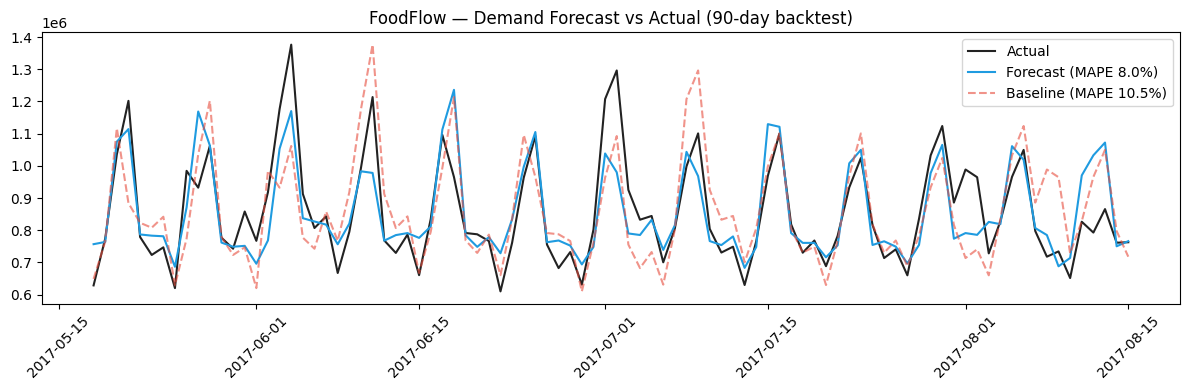

In [0]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.plot(test["date"], test["total_demand"].values, label="Actual", color="#222")
plt.plot(test["date"], pred, label=f"Forecast (MAPE {mm:.1f}%)", color="#1f9be0")
plt.plot(test["date"], baseline, label=f"Baseline (MAPE {bm:.1f}%)", color="#e74c3c", ls="--", alpha=.6)
plt.legend(); plt.title("FoodFlow — Demand Forecast vs Actual (90-day backtest)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()